In [2]:
import serial
import MotoricaInterface as mi
import time
import numpy as np
import matplotlib.pyplot as plt
import ubi4_enum_description
import p2p_high_level
%matplotlib ipympl

%load_ext autoreload
%autoreload 2


In [3]:
mi.utils.list_devices()

,device,name,description,hwid,vid,pid,serial_number,location,manufacturer,product,interface
0,/dev/cu.BLTH,cu.BLTH,n/a,n/a,NaN,NaN,None,None,None,None,None
1,/dev/cu.BoseQC35II,cu.BoseQC35II,n/a,n/a,NaN,NaN,None,None,None,None,None
2,/dev/cu.Bluetooth-Incoming-Port,cu.Bluetooth-Incoming-Port,n/a,n/a,NaN,NaN,None,None,None,None,None
3,/dev/cu.usbmodem1234561,cu.usbmodem1234561,Espressif Device,USB VID:PID=303A:4001 SER=123456 LOCATION=20-4,12346.0,16385.0,123456,20-4,Espressif Systems,Espressif Device,None


In [16]:
from ubi4_stack import Ubi4Stack
import ubi4_enum_description
    
ubi4_stack = Ubi4Stack('/dev/cu.usbmodem1234561')
ubi4_stack.initialize_stack()

assert "DCE_OMG_MODULE" in [ubi4_enum_description.device_codes_enum(sub_device.DeviceCode).name 
                            for sub_device in ubi4_stack.sub_devices_array], "DCE_OMG_MODULE not found"


['0x20', '0x08', '0x00', '0x01', '0x00', '0xbc', '0x00', '0x02']
Streaming stopped
Serial flushed
Serial flushed
Requesting first info blocked
Sending: ['0x00', '0x01', '0x00', '0x02', '0x00', '0x78', '0x00', '0x01', '0x02']
FullInitializeConnectionStruct loaded
Requesting device parameters: ['0x00', '0x01', '0x00', '0x03', '0x00', '0x31', '0x00', '0x02', '0x00', '0x0a']
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 1), ('package_id', 0), ('package_size', 67), ('crc', 127), ('address', 0)]) b'\x02\x00\x04\x00\x00\x00\x00\x01\x00\x00\x00\x00\x04\x01\x13\x08\x00\x00\x00\x01\x00\x1e\x00\x06\x00\x00\x00\x00(\x01\x19\x00\x00\x00\x00\x02\x00\x02\x00\x01\x00\x00\x00\x00\x04\x01\x13\x00\x01\x00\x00\x03\x00%\x00\x01\x00\x00\x00\x00\x04\x01\x13\x00\x01\x00\x00' 92
Sending: ['0x00', '0x01', '0x00', '0x01', '0x00', '0x3f', '0x00', '0x05']
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 1), (

In [17]:
display(ubi4_stack)

for sub_device in ubi4_stack.sub_devices_array:
    print('--------------SUBDEVICE------------------')
    display(sub_device)

UBI4Stack
ser=/dev/cu.usbmodem1234561
DeviceName: UBIv4_FEST_FO
DeviceVersion: 1
DeviceSubVersion: 0
DeviceLabel: t
DeviceType: 2
DeviceCode: 2
DeviceAddress: 255
DeviceUUID_Prefix: CPU MODULE
DeviceUUID: 1234567
ParametrsNum: 4
SubDeviceNum: 5
ProgramType: 1
DefaultPort: 0
5 subdevices found
Parameters:
	(PDCE_SIMPLE_COMMAND:1 bytes)
	(PDCE_ACTION_REQUEST:6 bytes)
	(PDCE_SELECT_PROFILE:1 bytes)
	(PDCE_INTERFECE_ERROR_COUNTER:1 bytes)

--------------SUBDEVICE------------------


DeviceType=37 : DTE_OMG_MULTY_CH
DeviceCode=7 : DCE_OMG_MODULE
DeviceRole=7 : DRE_OMG
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=10
ParametersNum=8
SubDeviceNum=0
DefaultPort=2
Parameters:
	(PDCE_SIMPLE_COMMAND:4 bytes)
	(PDCE_ACTION_REQUEST:6 bytes)
	(PDCE_EMG_CH_1_3_VAL:2 bytes)
	(PDCE_EMG_ENV_E_VAL:8 bytes)
	(PDCE_DMS_OUTPUT:1 bytes)
	(PDCE_OPTIC_LEARNING_DATA:156 bytes)
	(PDCE_OPTIC_CHECKPOINT_DATA_RECEIVER:104 bytes)
	(255:6 bytes)

--------------SUBDEVICE------------------


DeviceType=81 : DTE_BMS
DeviceCode=5 : DCE_BMS
DeviceRole=6 : DRE_BMS
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=7
ParametersNum=2
SubDeviceNum=0
DefaultPort=1
Parameters:
	(PDCE_BMS_STATUS_COMBINED_PARAM:4 bytes)
	(PDCE_DATE_AND_TIME:8 bytes)

--------------SUBDEVICE------------------


DeviceType=18 : DTE_MOTOR_DRIVER_MULTY_CH
DeviceCode=2 : DCE_FEST_H_AND_F
DeviceRole=2 : DRE_DISPLAY
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=6
ParametersNum=13
SubDeviceNum=0
DefaultPort=0
Parameters:
	(PDCE_SIMPLE_COMMAND:1 bytes)
	(PDCE_GLOBAL_FORCE:1 bytes)
	(PDCE_OPEN_CLOSE_THRESHOLD:4 bytes)
	(PDCE_UNIVERSAL_CONTROL_INPUT:1 bytes)
	(PDCE_EMG_CH_1_3_VAL:2 bytes)
	(PDCE_CONTROL_MODE_SETTINGS:1 bytes)
	(PDCE_GESTURE_GROUP:16 bytes)
	(PDCE_SELECT_GESTURE:1 bytes)
	(PDCE_SELECT_PROFILE:1 bytes)
	(PDCE_CURRENT_DRIVE_POSITION:6 bytes)
	(PDCE_CURRENT_DRIVE_CURRENT_UINT8:6 bytes)
	(PDCE_GESTURE_SETTINGS:26 bytes)
	(PDCE_CALIBRATION_CURRENT_PERCENT:1 bytes)

--------------SUBDEVICE------------------


DeviceType=68 : DTE_DISPLAY_BUTTONS
DeviceCode=6 : DCE_GUI
DeviceRole=2 : DRE_DISPLAY
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=9
ParametersNum=17
SubDeviceNum=0
DefaultPort=1
Parameters:
	(PDCE_ACTION_REQUEST:6 bytes)
	(PDCE_GESTURE_GROUP:16 bytes)
	(PDCE_SELECT_GESTURE:1 bytes)
	(PDCE_SELECT_PROFILE:1 bytes)
	(PDCE_GLOBAL_FORCE:1 bytes)
	(PDCE_GLOBAL_SENSITIVITY:1 bytes)
	(PDCE_GLOBAL_THRESHOLD:1 bytes)
	(PDCE_OPEN_CLOSE_THRESHOLD:4 bytes)
	(PDCE_BMS_STATUS_COMBINED_PARAM:4 bytes)
	(PDCE_EMG_CH_1_3_VAL:2 bytes)
	(PDCE_EMG_CH_1_3_GAIN:2 bytes)
	(PDCE_EMG_ENV_E_VAL:8 bytes)
	(PDCE_DATE_AND_TIME:8 bytes)
	(PDCE_ENERGY_SAVE_MODE:1 bytes)
	(PDCE_LEFT_RIGHT_HAND_MODE:4 bytes)
	(PDCE_SIMPLE_COMMAND:0 bytes)
	(PDCE_SIMPLE_COMMAND:0 bytes)

--------------SUBDEVICE------------------


DeviceType=34 : DTE_EMG_2CH
DeviceCode=4 : DCE_EMG_SENSE
DeviceRole=8 : DRE_HAND_OPEN_SENSOR
DeviceVersion=1
DeviceSubVersion=0
DeviceAddress=8
ParametersNum=5
SubDeviceNum=0
DefaultPort=1
Parameters:
	(PDCE_EMG_CH_1_3_VAL:2 bytes)
	(PDCE_GLOBAL_SENSITIVITY:1 bytes)
	(PDCE_EMG_CH_1_3_GAIN:2 bytes)
	(PDCE_EMG_ENV_E_VAL:8 bytes)
	(PDCE_SWITCH_SENSORS:1 bytes)

# Work with optics

In [18]:
ubi4_stack.start_parsing_thread()
time.sleep(1)

Starting parsing thread
Serial flushed
Parsing thread started successfully


In [19]:
ubi4_stack.start_streaming()

['0x20', '0x08', '0x00', '0x01', '0x00', '0x5e', '0x00', '0x01']
Streaming started


b''

In [20]:
ubi4_stack.ser.write(bytes([0x60, 0x80, 0x00, 0x01, 0x00, 0x00, 0x0A, 0x02]))


8

In [21]:
import struct
import socket

teleplotAddr = ("127.0.0.1", 47269)
sock = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)

def sendTelemetry(name, value):
	msg = name+":"+str(value)
	sock.sendto(msg.encode(), teleplotAddr)
     

addresses_devices_map = {subdevice.DeviceAddress: subdevice 
                         for subdevice in ubi4_stack.sub_devices_array}

addresses_names_map = {a: ubi4_enum_description.device_codes_enum(d.DeviceCode).name 
                           for a, d in addresses_devices_map.items()}

addresses_devices_map[0x00] = ubi4_stack 
addresses_names_map[0x00] = ubi4_enum_description.device_codes_enum(1).name

print(addresses_names_map)

ubi4_stack.pack_history.clear()
ubi4_stack.flush_serial()

ubi4_states = {}

_ubi4_state = {}

n_states = 0
while True:
    if len(ubi4_stack.pack_history) > 0:
        pack_ts, pack = ubi4_stack.pack_history.popleft()
        try:
            pack_header, pack_payload = p2p_high_level.parse_p2p_high_level_port_pack(pack)
        except p2p_high_level.P2P_PACK_SIZE_MISMATCH_ERROR:
            print(f'Pack size mismatch: {len(pack)}')
            raise Exception(f'Pack size mismatch: {len(pack)}')
            continue
        except Exception as e:
            print(e)
            print(f'Error: {e}')
            continue
    
        if ubi4_enum_description.Command_enum(pack_header['package_code']).name == 'COMPLEX_PARAMETER_TRANSFER':
            print(f'n_states: {n_states: >5}', end = ' '*50 + '\r')
            n_states += 1 
            _ubi4_state = {}
            while len(pack_payload)>0:
                device_address = pack_payload[0]
                device_code_name = addresses_names_map[device_address]

                device_parameter_id = pack_payload[1]
                try:
                    device_parameter_name = ubi4_enum_description.parameter_data_code_enum(ubi4_stack.__device_addresses_map__[device_address].parsed_parameters[device_parameter_id].DataCode).name
                except Exception as e:
                    device_parameter_name = str(ubi4_stack.__device_addresses_map__[device_address].parsed_parameters[device_parameter_id].DataCode)
                    
                vec_index = (device_code_name, device_parameter_name)

                if not vec_index in _ubi4_state:
                    _ubi4_state[vec_index] = {}

                device_parameter_width = ubi4_stack.__device_addresses_map__[device_address].parsed_parameters[device_parameter_id].parameter_size
                # _ubi4_state[vec_index]['width'] = device_parameter_width

                payload_chunk = pack_payload[2:2+device_parameter_width]
                # _ubi4_state[vec_index]['payload_chunk'] = payload_chunk

                pack_values = ubi4_stack.parse_parameter_values(payload_chunk, device_code_name, device_parameter_name)
                # _ubi4_state[vec_index]['pack_values'] = pack_values

                _ubi4_state[vec_index] = pack_values

                pack_payload = pack_payload[2+device_parameter_width:]

            ubi4_states[time.time()] = _ubi4_state.copy()

            if ('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA') in _ubi4_state:
                for i in list(range(2,2+16)):
                    sendTelemetry(f'omg_learning_data_{i}', _ubi4_state[('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')][i])
                for i in list(range(2+16,2+16+2)):
                    sendTelemetry(f'emg_learning_data{i}', _ubi4_state[('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')][i])
                for i in list(range(2+16+8+3,2+16+8+3+8)):
                    sendTelemetry(f'prb_{i}', _ubi4_state[('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')][i])
                for i in list(range(2+16+8+3+8,2+16+8+3+8+2)):
                    sendTelemetry(f'class_{i}', _ubi4_state[('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')][i])
                    
            # if ('DCE_EMG_SENSE', 'PDCE_EMG_CH_1_3_VAL') in _ubi4_state:
            #     (emg_a, emg_b) = _ubi4_state[('DCE_EMG_SENSE', 'PDCE_EMG_CH_1_3_VAL')]
            #     sendTelemetry('emg_a', emg_a)
            #     sendTelemetry('emg_b', emg_b)      

            if ('DCE_OMG_MODULE', 'PDCE_DMS_OUTPUT') in _ubi4_state:
                dms_output = _ubi4_state[('DCE_OMG_MODULE', 'PDCE_DMS_OUTPUT')]
                sendTelemetry('dms_output', dms_output)                

        else:
            raise Exception(f'Unknown package code: {pack_header["package_code"]}')
                
        
    else:
        time.sleep(0.010)

{10: 'DCE_OMG_MODULE', 7: 'DCE_BMS', 6: 'DCE_FEST_H_AND_F', 9: 'DCE_GUI', 8: 'DCE_EMG_SENSE', 0: 'DCE_CPU_MODULE'}
Serial flushed


KeyboardInterrupt: 

In [58]:
import pandas as pd
df_states = pd.DataFrame(ubi4_states).T
df_states.index.name='timestamp'
df_states.index -= df_states.index[0]
df_states.ffill(inplace=True, axis=0)
df_states.bfill(inplace=True, axis=0)

df_states


/var/folders/8n/n_m859_90sv0qfnb23lkzb3h0000gn/T/ipykernel_77024/3127667822.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_states.ffill(inplace=True, axis=0)


,DCE_OMG_MODULE,DCE_EMG_SENSE,DCE_OMG_MODULE,DCE_FEST_H_AND_F
,PDCE_OPTIC_LEARNING_DATA,PDCE_EMG_CH_1_3_VAL,PDCE_DMS_OUTPUT,PDCE_SELECT_GESTURE
timestamp,,,,
0.000000,"(11551.0, 19.0, 15525834.0, 15551817.0, 155705...","(55, 40)",1.0,4.0
0.037399,"(11591.0, 19.0, 15524572.0, 15551953.0, 155713...","(55, 40)",1.0,4.0
0.081631,"(11631.0, 19.0, 15524842.0, 15551330.0, 155705...","(55, 40)",1.0,4.0
0.125111,"(11671.0, 19.0, 15524137.0, 15551845.0, 155714...","(55, 40)",1.0,4.0
0.159130,"(11711.0, 19.0, 15524606.0, 15551829.0, 155707...","(55, 40)",1.0,4.0
...,...,...,...,...
51.002972,"(62551.0, 17.0, 15529598.0, 15556507.0, 155722...","(0, 0)",0.0,1.0
51.046963,"(62591.0, 17.0, 15529382.0, 15556751.0, 155729...","(0, 0)",0.0,1.0


Text(0.5, 1.0, 'DMS output')

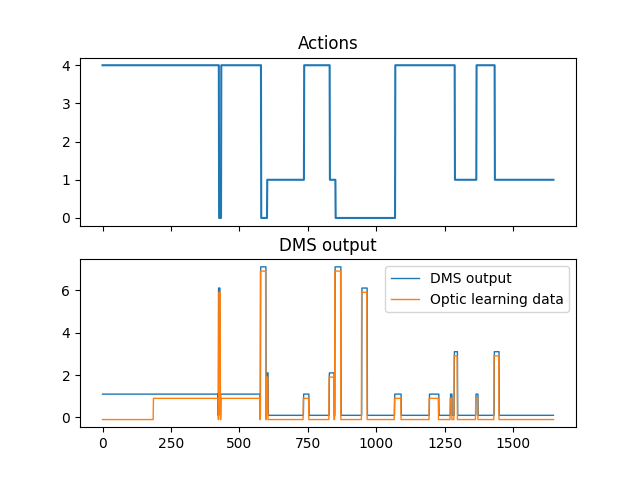

Exception in thread Thread-32 (parsing_thread):
Traceback (most recent call last):
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/site-packages/serial/serialposix.py", line 575, in read
    buf = os.read(self.fd, size - len(read))
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: [Errno 6] Device not configured

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "/Users/mike/src/pyMotoricaInterface/Scripts/ubi4/ubi4_stack.py", line 283, in parsing_thread
    in_byte = self.ser.read(1)
              ^^^^^^^^^^^^^^^^
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/site-packages/serial/serialposix.py", line 581, in read
    raise SerialException('read failed: {}'.for

In [60]:
fig, axx = plt.subplots(2, 1,sharex=True)
plt.sca(axx[0])
plt.plot(df_states[('DCE_FEST_H_AND_F', 'PDCE_SELECT_GESTURE')].fillna(-1).values.astype(int))
plt.title('Actions')

plt.sca(axx[1])
plt.plot(df_states[('DCE_OMG_MODULE', 'PDCE_DMS_OUTPUT')].values+0.1, label='DMS output', lw=1)
plt.plot(df_states[('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')].apply(lambda x: x[-1] if not pd.isna(x) else None).values-0.1, label='Optic learning data', lw=1)
plt.legend()
plt.title('DMS output')


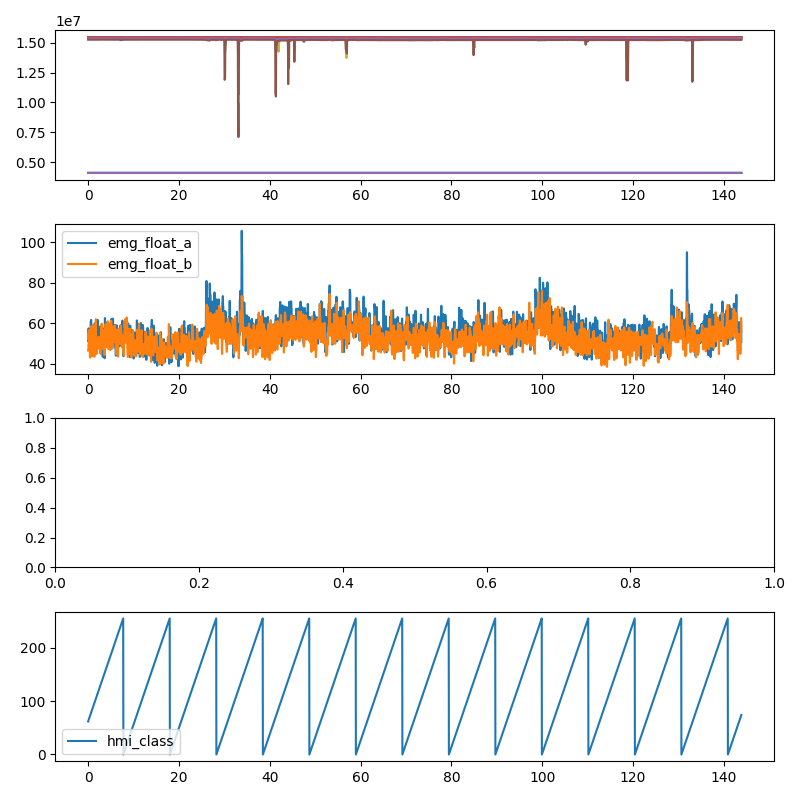

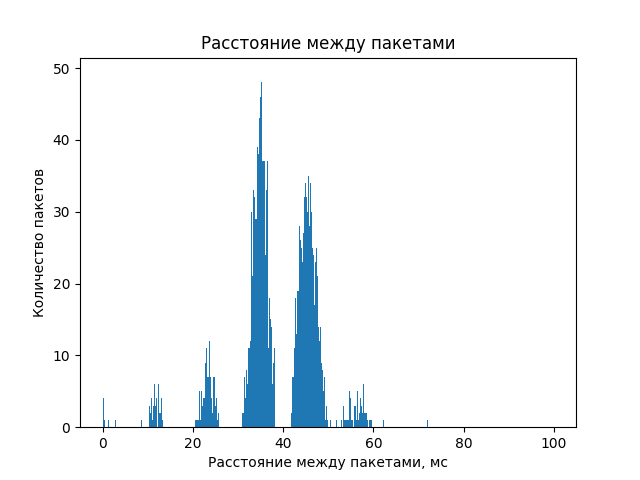

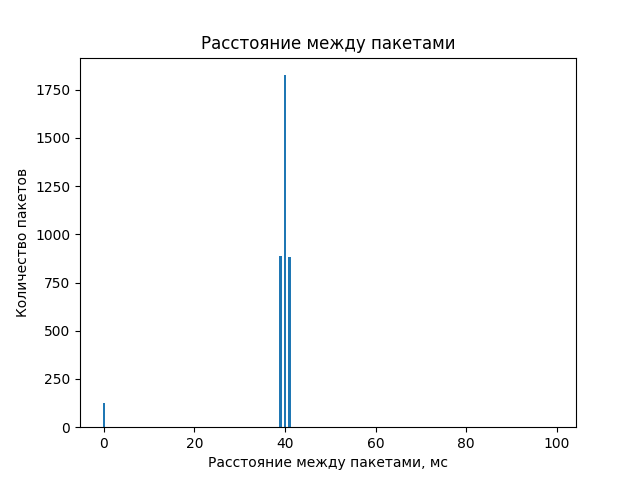

Exception in thread Thread-15 (parsing_thread):
Traceback (most recent call last):
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/site-packages/serial/serialposix.py", line 575, in read
    buf = os.read(self.fd, size - len(read))
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: [Errno 6] Device not configured

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "/Users/mike/src/pyMotoricaInterface/Scripts/ubi4/ubi4_stack.py", line 228, in parsing_thread
    in_byte = self.ser.read(1)
              ^^^^^^^^^^^^^^^^
  File "/usr/local/anaconda3/envs/opto3/lib/python3.11/site-packages/serial/serialposix.py", line 581, in read
    raise SerialException('read failed: {}'.for

In [53]:
emg_states = np.stack(df_states.loc[:, ('DCE_EMG_SENSE', 'PDCE_EMG_CH_1_3_VAL')], axis=0)
# errors = np.stack(df_states.loc[:, ('DCE_CPU_MODULE', 'PDCE_INTERFECE_ERROR_COUNTER')], axis=0)

hmi_states = np.stack(df_states.loc[:, ('DCE_OMG_MODULE', 'PDCE_OPTIC_LEARNING_DATA')], axis=0)
hmi_omg_states = hmi_states[:, :16]
hmi_emg_states = hmi_states[:, 16:18]
hmi_ts_ms = hmi_states[:, 18]
hmi_ts_ms -= hmi_ts_ms[0]
hmi_ts_s = hmi_ts_ms / 1000
hmi_class = hmi_states[:, 19]

fig, axx = plt.subplots(4, 1, figsize=(8, 8))
plt.sca(axx[0])
plt.plot(hmi_ts_s, hmi_omg_states)
# plt.legend(['omg_learning_data_'+str(i) for i in range(16)])

plt.sca(axx[1])
plt.plot(hmi_ts_s, hmi_emg_states)
plt.legend(['emg_float_a', 'emg_float_b'])

plt.sca(axx[2])
# plt.plot(hmi_ts_s, errors)
# plt.legend()

plt.sca(axx[3])
plt.plot(hmi_ts_s, hmi_class)
plt.legend(['hmi_class'])

plt.tight_layout()

plt.figure()
plt.hist(1000*df_states.index.diff().dropna(),bins=np.arange(0,100,0.1));
plt.title('Расстояние между пакетами');
plt.xlabel('Расстояние между пакетами, мс');
plt.ylabel('Количество пакетов');

plt.figure()
plt.hist(np.diff(hmi_ts_ms),bins=np.arange(0,100,0.5)-0.25);
plt.title('Расстояние между пакетами');
plt.xlabel('Расстояние между пакетами, мс');
plt.ylabel('Количество пакетов');

AttributeError: 'bytes' object has no attribute 'read'

In [37]:
pack_payload[-4:]

b'\x08\x00\x1b\x1b'

In [33]:
pack_header, pack_payload = p2p_high_level.parse_p2p_high_level_port_pack(pack, check_consistency=False)
pack_header, len(pack_payload)


(OrderedDict([('port', 0),
              ('waiting_answer', 0),
              ('request_type', 0),
              ('brige', 0),
              ('package_code', 9),
              ('package_id', 0),
              ('package_size', 78),
              ('crc', 216),
              ('address', 0)]),
 78)

In [145]:
p2p_high_level.parse_p2p_high_level_port_pack(pack, check_consistency=False)

(OrderedDict([('port', 3),
              ('waiting_answer', 0),
              ('request_type', 0),
              ('brige', 0),
              ('package_code', 0),
              ('package_id', 72),
              ('package_size', 0),
              ('crc', 3),
              ('address', 60)]),
 bytearray(b''))

In [100]:
pack_header, pack_payload

(OrderedDict([('port', 0),
              ('waiting_answer', 0),
              ('request_type', 0),
              ('brige', 0),
              ('package_code', 9),
              ('package_id', 0),
              ('package_size', 74),
              ('crc', 32),
              ('address', 0)]),
 bytearray(b'\n\x054\x03|Jl\xbb{J\xe4\xdc{J\xb4?{J\xb4\xe8{J(\xc2{J\x04\xcf{J\x90\xa9{J\xd4\xc7{JXC\xa1J\x0c\xb5}J\xbc\xd3}J\xa8\x84|Jp\xf1\x80J\xa3\xbaiK\xf3MhK\x00\x00\x00\x00\x00\x00\x00\x00'))

In [101]:
72//4

18

In [35]:
pack_header

OrderedDict([('port', 0),
             ('waiting_answer', 0),
             ('request_type', 0),
             ('brige', 0),
             ('package_code', 9),
             ('package_id', 0),
             ('package_size', 406),
             ('crc', 88),
             ('address', 0)])

In [92]:
ubi4_enum_description.device_roles_enum['DRE_OMG'].value

7

In [81]:
ubi4_enum_description.device_types_enum._member_names_

['DTE_UNKNOW',
 'DTE_CPU',
 'DTE_SUB_CPU',
 'DTE_DRIVER',
 'DTE_MOTOR_DRIVER',
 'DTE_MOTOR_DRIVER_MULTY_CH',
 'DTE_SENSOR',
 'DTE_EMG_1CH',
 'DTE_EMG_2CH',
 'DTE_EMG_MULTY_CH',
 'DTE_OMG_SEGMENT',
 'DTE_OMG_MULTY_CH',
 'DTE_OMG_EMG_SEGMENT',
 'DTE_OMG_EMG_MULTY_CH',
 'DTE_STIMULATOR',
 'DTE_HMI',
 'DTE_DISPLAY',
 'DTE_BUTTONS',
 'DTE_SOUNDS',
 'DTE_DISPLAY_BUTTONS',
 'DTE_DISPLAY_SOUNDS',
 'DTE_BUTTONS_SOUNDS',
 'DTE_DISPLAY_BUTTONS_SOUNDS',
 'DTE_TOUCH_DISPLAY',
 'DTE_TOUCH_DISPLAY_SOUNDS',
 'DTE_POWER',
 'DTE_BMS',
 'DTE_ACB',
 'DTE_POWER_CONVERTER',
 'DTE_POWER_ISOLATOR',
 'DTE_POWER_COMBO',
 'DTE_COMBO',
 'DTE_OTHER']

In [79]:
ubi4_enum_description.device_roles_enum['DRE_OMG'].value

7

In [26]:
import pandas as pd

pack_data = []

for p in pack_history:
    try:
        p2p_high_level.check_p2p_pack_consistency(p[1])
    except Exception as e:
        print(f'Error: {e}')
        continue

    pack_header, pack_payload = p2p_high_level.parse_p2p_high_level_port_pack(p[1])
    d_header = dict(pack_header)
    d_header['payload'] = pack_payload
    d_header['ts'] = p[0]
    pack_data.append(d_header)

    print(pack_header, pack_payload)

df_packs = pd.DataFrame(pack_data)
df_packs['ts_diff'] = df_packs['ts'].diff()
df_packs


Error: 
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 216), ('address', 0)]) bytearray(b'\x08\x00\x01\x00')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 28), ('address', 0)]) bytearray(b'\x08\x00\x00\x00')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 66), ('address', 0)]) bytearray(b'\x08\x00\x00\x01')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 28), ('address', 0)]) bytearray(b'\x08\x00\x00\x00')
OrderedDict([('port', 0), ('waiting_answer', 0), ('request_type', 0), ('brige', 0), ('package_code', 9), ('package_id', 0), ('package_size', 4), ('crc', 142), ('addres

,port,waiting_answer,request_type,brige,package_code,package_id,package_size,crc,address,payload,ts,ts_diff
0,0,0,0,0,9,0,4,216,0,"[8, 0, 1, 0]",1.734035e+09,NaN
1,0,0,0,0,9,0,4,28,0,"[8, 0, 0, 0]",1.734035e+09,7.520163
2,0,0,0,0,9,0,4,66,0,"[8, 0, 0, 1]",1.734035e+09,0.080663
3,0,0,0,0,9,0,4,28,0,"[8, 0, 0, 0]",1.734035e+09,2.639304
4,0,0,0,0,9,0,4,142,0,"[8, 0, 0, 151]",1.734035e+09,0.079805
5,0,0,0,0,9,0,4,180,0,"[8, 0, 0, 239]",1.734035e+09,0.080045
6,0,0,0,0,9,0,4,124,0,"[8, 0, 3, 255]",1.734035e+09,0.079788
7,0,0,0,0,9,0,4,226,0,"[8, 0, 98, 255]",1.734035e+09,0.090066
8,0,0,0,0,9,0,4,231,0,"[8, 0, 67, 255]",1.734035e+09,0.070153
9,0,0,0,0,9,0,4,121,0,"[8, 0, 34, 255]",1.734035e+09,0.079519
